# 03 · Líneas base tabulares — M0 (diámetro)

**M0** es la línea base de la Tabla 21 del TFM: se trata de hacer una regresión logística con el diámetro del nódulo. Es la referencia mínima que debe superar el modelo de imagen (H1).

Este notebook no contiene lógica de entrenamiento. Llama a `tfm_lidc.lineas_base.ejecutar`, que es el mismo código que se lanza desde la terminal, y se dedica a mostrar y analizar los resultados. M1 y M2 se añadirán como secciones nuevas con su propio archivo de configuración.

| Elemento | Decisión (Tabla 19) |
|---|---|
| Unidad | Nódulo con etiqueta R1 (≥ 3 lectores; mediana < 3 baja, > 3 alta, = 3 excluido) |
| Partición | 5 pliegues externos agrupados por paciente y estratificados; validación interna ≈ 16 % por pliegue |
| Umbral | Youden en la validación interna de cada pliegue |
| Métricas | Sobre las predicciones fuera de pliegue; IC 95 % por bootstrap de pacientes |

**Requisitos:** kernel «Python (TFM)» con el paquete instalado (`pip install -e ".[dev]"`) y la partición versionada en `particiones/`.

## 0. Configuración

In [1]:
%load_ext autoreload
%autoreload 2

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
from sklearn.calibration import calibration_curve

from tfm_lidc import config
from tfm_lidc.data import nodulos as dn
from tfm_lidc.lineas_base import ejecutar

# Raíz del repositorio: la primera carpeta hacia arriba que contiene pyproject.toml
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CFG_M0 = REPO / "configs/modelos/m0_diametro.yaml"
N_CONTROL = 200          # repeticiones del control negativo (0 para omitirlo)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("Repositorio:", REPO)

Matplotlib is building the font cache; this may take a moment.


Repositorio: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai


## 1. Ejecución de M0

In [2]:
r = ejecutar(str(CFG_M0), n_control=N_CONTROL)
cfg = config.cargar(CFG_M0)
d = r["datos"]
print(f"{r['modelo']} · {d['regla']} · {d['nodulos']} nódulos de {d['pacientes']} pacientes · "
      f"{d['alta_sospecha']} de alta sospecha ({d['alta_sospecha']/d['nodulos']:.1%})")
print(f"Partición: huella {d['huella_particion']} · commit {r['commit']} · {r['entorno']['maquina']}")
print(f"Resultados en: {r['carpeta_resultados']}")

M0 · R1 · 879 nódulos de 535 pacientes · 430 de alta sospecha (48.9%)
Partición: huella 72fee378f8009b96 · commit 7d1dbaa-modificado · macOS-26.7.2-arm64-arm-64bit
Resultados en: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai/resultados/m0_diametro__R1__s42__7d1dbaa-modificado


## 2. Métricas de prueba con IC 95 %

In [3]:
nombres = dict(auc="AUC", auprc="AUPRC", brier="Brier (menor es mejor)", exactitud="Exactitud",
               sensibilidad="Sensibilidad", especificidad="Especificidad")
tabla = pd.DataFrame([dict(métrica=nombres[k], valor=v["valor"], ic95_inf=v["ic95"][0], ic95_sup=v["ic95"][1])
                      for k, v in r["metricas"].items()]).set_index("métrica")
tabla.round(3)

,valor,ic95_inf,ic95_sup
métrica,,,
AUC,0.937,0.920,0.953
AUPRC,0.931,0.908,0.952
Brier (menor es mejor),0.100,0.087,0.115
Exactitud,0.862,0.839,0.885
Sensibilidad,0.835,0.798,0.870
Especificidad,0.889,0.857,0.919


## 3. Resultados por pliegue

In [4]:
pred = pd.read_csv(Path(r["carpeta_resultados"]) / "predicciones_oof.csv")
por_pliegue = pred.groupby("pliegue").agg(nódulos=("nodule_id", "size"), pacientes=("patient_id", "nunique"),
                                          alta_sospecha=("etiqueta", "mean"))
por_pliegue["AUC prueba"] = r["auc_prueba_por_pliegue"]
por_pliegue["umbral"] = r["umbrales_por_pliegue"]
por_pliegue["coef. diámetro (est.)"] = [c["diametro_mm"] for c in r["coeficientes_por_pliegue"]]
por_pliegue["intercepto"] = [c["intercepto"] for c in r["coeficientes_por_pliegue"]]
display(por_pliegue.round({"alta_sospecha": 3, "AUC prueba": 3, "umbral": 3, "coef. diámetro (est.)": 3, "intercepto": 3}))
a = np.array(r["auc_prueba_por_pliegue"])
print(f"AUC entre pliegues: media {a.mean():.3f} · DT {a.std(ddof=1):.3f} · rango {a.min():.3f}–{a.max():.3f}")

,nódulos,pacientes,alta_sospecha,AUC prueba,umbral,coef. diámetro (est.),intercepto
pliegue,,,,,,,
0,161,103,0.534,0.934,0.653,4.201,0.961
1,178,112,0.461,0.920,0.457,4.139,1.034
2,168,101,0.518,0.926,0.318,3.903,0.830
3,188,112,0.511,0.924,0.360,3.857,0.741
4,184,107,0.429,0.969,0.626,3.574,0.820


AUC entre pliegues: media 0.935 · DT 0.020 · rango 0.920–0.969


## 4. Curvas ROC, calibración y relación con el diámetro

* **ROC:** curva conjunta de las 879 predicciones fuera de pliegue y la de cada pliegue.
* **Calibración:** proporción observada de alta sospecha frente a la probabilidad predicha (10 intervalos).
* **Probabilidad frente a diámetro:** la curva logística de M0 (una por pliegue) y, en los extremos, cada nódulo según su clase real; las líneas verticales marcan el diámetro equivalente al umbral de cada pliegue. Los nódulos de una clase que caen al otro lado de esas líneas son los errores de M0.

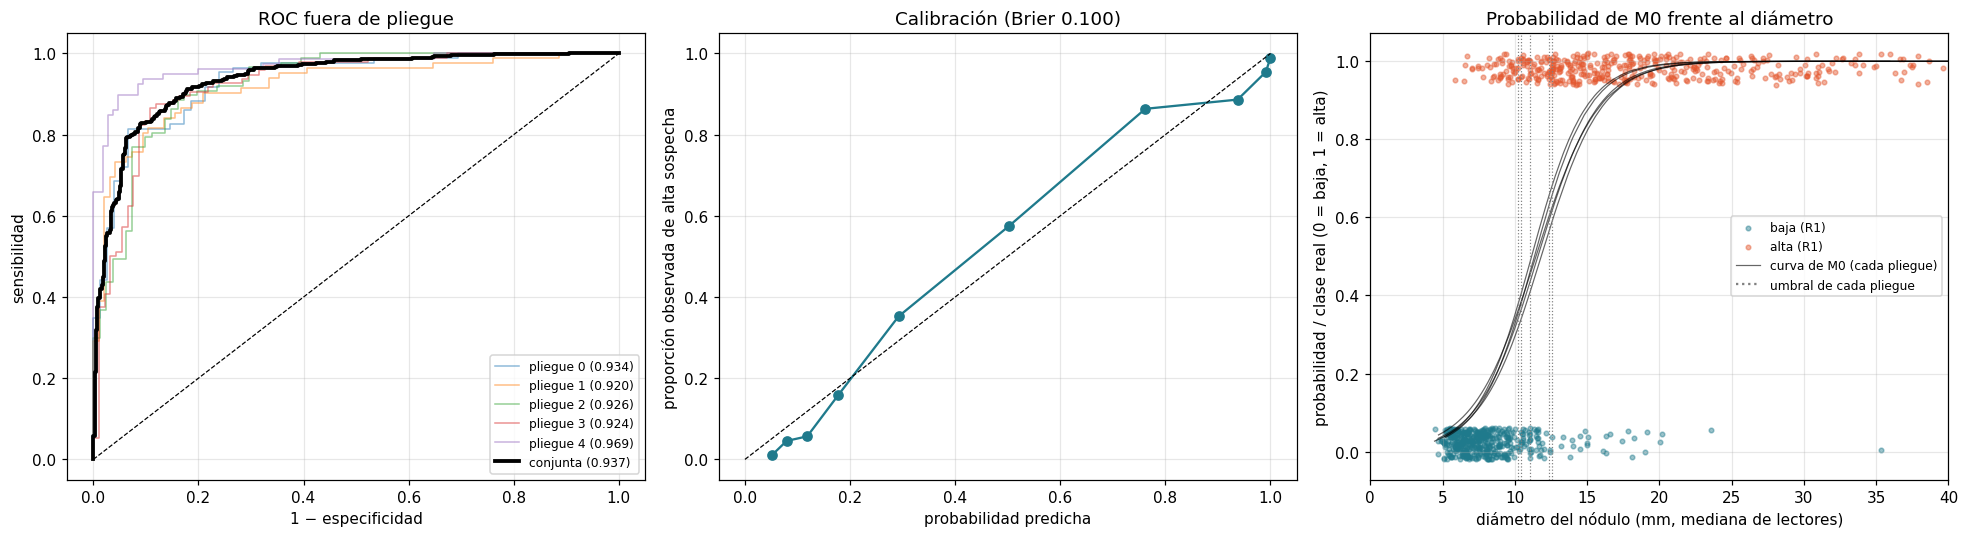

Diámetro equivalente al umbral de cada pliegue (mm): [12.3 11.  10.2 10.4 12.6]


In [5]:
nod = dn.construir_o_cargar(cfg, REPO / cfg["salidas"]["dir_resultados"] / "datos")
pred = pred.merge(nod[["nodule_id", "diametro_mm"]], on="nodule_id", validate="one_to_one")
y, p = pred.etiqueta.values, pred.probabilidad.values

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for k, g in pred.groupby("pliegue"):
    f, t, _ = roc_curve(g.etiqueta, g.probabilidad)
    ax[0].plot(f, t, lw=1, alpha=.5, label=f"pliegue {k} ({r['auc_prueba_por_pliegue'][k]:.3f})")
f, t, _ = roc_curve(y, p)
ax[0].plot(f, t, lw=2.5, c="k", label=f"conjunta ({roc_auc_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set(title="ROC fuera de pliegue", xlabel="1 − especificidad", ylabel="sensibilidad"); ax[0].legend(fontsize=8)

obs, esp = calibration_curve(y, p, n_bins=10, strategy="quantile")
ax[1].plot(esp, obs, "o-", c="#1f7a8c"); ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
ax[1].set(title=f"Calibración (Brier {r['metricas']['brier']['valor']:.3f})", xlabel="probabilidad predicha",
          ylabel="proporción observada de alta sospecha")

rng = np.random.default_rng(0)
for etq, col, lab in ((0, "#1f7a8c", "baja (R1)"), (1, "#e4572e", "alta (R1)")):
    g = pred[pred.etiqueta == etq]
    ax[2].scatter(g.diametro_mm, etq + rng.uniform(-.04, .04, len(g)) * (1 if etq == 0 else -1) + (0.02 if etq == 0 else -0.02),
                  c=col, s=9, alpha=.45, label=lab)
for k, g in pred.groupby("pliegue"):
    g = g.sort_values("diametro_mm")
    ax[2].plot(g.diametro_mm, g.probabilidad, c="k", lw=.8, alpha=.6, label="curva de M0 (cada pliegue)" if k == 0 else None)
for k, u in enumerate(r["umbrales_por_pliegue"]):
    g = pred[pred.pliegue == k].sort_values("diametro_mm")
    corte = np.interp(u, g.probabilidad.values, g.diametro_mm.values)   # la curva es monótona creciente
    ax[2].axvline(corte, c="grey", lw=.8, ls=":")
ax[2].set(title="Probabilidad de M0 frente al diámetro", xlabel="diámetro del nódulo (mm, mediana de lectores)",
          ylabel="probabilidad / clase real (0 = baja, 1 = alta)", xlim=(0, 40))
ax[2].plot([], [], c="grey", ls=":", label="umbral de cada pliegue"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

cortes = []
for k, u in enumerate(r["umbrales_por_pliegue"]):
    g = pred[pred.pliegue == k].sort_values("diametro_mm")
    cortes.append(np.interp(u, g.probabilidad.values, g.diametro_mm.values))
print("Diámetro equivalente al umbral de cada pliegue (mm):", np.round(cortes, 1))

## 5. Matriz de confusión y análisis de errores

,predicho: baja,predicho: alta
real: baja,399,50
real: alta,71,359


,nódulos,25%,mediana,75%
resultado,,,,
FN,71.0,8.8,9.6,10.5
FP,50.0,11.4,12.9,16.2
VN,399.0,6.3,7.2,8.4
VP,359.0,14.5,18.6,24.5


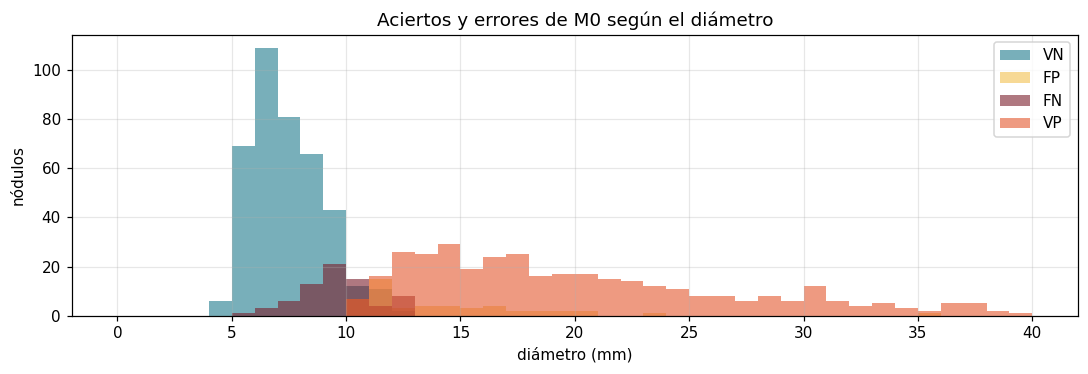

Los falsos negativos son nódulos de alta sospecha pequeños y los falsos positivos, de baja sospecha grandes: es el margen que el modelo de imagen tendría que recuperar para superar a M0 (H1).


In [6]:
cm = confusion_matrix(pred.etiqueta, pred.prediccion)
display(pd.DataFrame(cm, index=["real: baja", "real: alta"], columns=["predicho: baja", "predicho: alta"]))

pred["resultado"] = np.select(
    [(pred.etiqueta == 1) & (pred.prediccion == 1), (pred.etiqueta == 0) & (pred.prediccion == 0),
     (pred.etiqueta == 0) & (pred.prediccion == 1)], ["VP", "VN", "FP"], "FN")
display(pred.groupby("resultado").diametro_mm.describe()[["count", "25%", "50%", "75%"]].round(1)
        .rename(columns={"count": "nódulos", "50%": "mediana"}))

fig, ax = plt.subplots(figsize=(10, 3.5))
for res, c in (("VN", "#1f7a8c"), ("FP", "#f2c14e"), ("FN", "#7a1f2b"), ("VP", "#e4572e")):
    ax.hist(pred.diametro_mm[pred.resultado == res], bins=np.arange(0, 41, 1), alpha=.6, label=res, color=c)
ax.set(xlabel="diámetro (mm)", ylabel="nódulos", title="Aciertos y errores de M0 según el diámetro"); ax.legend()
plt.tight_layout(); plt.show()
print("Los falsos negativos son nódulos de alta sospecha pequeños y los falsos positivos, de baja sospecha grandes: "
      "es el margen que el modelo de imagen tendría que recuperar para superar a M0 (H1).")

## 6. Control negativo

M0 se reentrena con las etiquetas de entrenamiento permutadas y se evalúa contra las etiquetas reales de prueba (Tabla 19). Sin fuga, el AUC medio debe rondar 0,5.

Con una sola variable el modelo solo puede aprender el signo de la relación, así que el AUC salta entre valores altos y bajos. En M0 la prueba es poco informativa; será relevante en M3–M7.

In [7]:
c = r["control_negativo"]
if c:
    print(f"{c['n_permutaciones']} permutaciones · AUC media {c['auc_media']:.3f} · "
          f"percentiles 2,5–97,5 %: [{c['auc_p2_5']:.3f}, {c['auc_p97_5']:.3f}] · "
          f"{'superado' if c['superado'] else 'NO superado'}")
else:
    print("Control negativo omitido (N_CONTROL = 0)")

200 permutaciones · AUC media 0.467 · percentiles 2,5–97,5 %: [0.215, 0.735] · superado


## 7. Comprobación de los datos frente a Hancock y Magnan (2016) — opcional

El artículo no tiene un modelo solo con el diámetro, pero su experimento uno permite validar la lectura de LIDC-IDRI: con su protocolo (anotación como unidad, sin la publicación inicial, 75/25 aleatorio) deben salir su cohorte (2.817 anotaciones de 530 exploraciones) y su Tabla 4. No forma parte del protocolo del TFM. Tarda 1–2 minutos con 1.000 repeticiones.

In [8]:
EJECUTAR_REPLICA = False
if EJECUTAR_REPLICA:
    import subprocess, sys
    print(subprocess.run([sys.executable, str(REPO / "scripts/replica_hancock_magnan.py"), "--repeticiones", "1000"],
                         capture_output=True, text=True).stdout)
else:
    print("Réplica omitida: cambia EJECUTAR_REPLICA a True para ejecutarla.")

Réplica omitida: cambia EJECUTAR_REPLICA a True para ejecutarla.


## 8. Registro de la ejecución

Todo lo necesario para auditar el resultado queda en `registro.json`: configuración y su huella, commit, huella de la partición, umbrales, coeficientes, métricas y entorno.

In [9]:
print(json.dumps({k: r[k] for k in ("experimento", "commit", "fecha", "huella_configuracion", "entorno", "duracion_s")},
                 indent=1, ensure_ascii=False))

{
 "experimento": "m0_diametro__R1__s42__7d1dbaa-modificado",
 "commit": "7d1dbaa-modificado",
 "fecha": "2026-11-09 21:11:05",
 "huella_configuracion": "a396ecdd2cb5",
 "entorno": {
  "python": "3.11.18",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "sklearn": "1.7.2",
  "maquina": "macOS-26.7.2-arm64-arm-64bit"
 },
 "duracion_s": 4.1
}
